In [ ]:
from google.colab import drive
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib as mpl
import matplotlib.pyplot as plt
import random
import regex as re

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
cd /content/drive/MyDrive/colab_notebooks

/content/drive/MyDrive/colab_notebooks


In [ ]:
# chrs = list(set(text))
# chrs.sort()

# stoi = {c:i for i, c in enumerate(chrs)}
# itos = {i:c for c, i in stoi.items()}

# def encode(text):
#   return torch.tensor([stoi[c] for c in text])
# def decode(enc):
#   return "".join([itos[i] for i in enc.tolist()])

# data = encode(text)

# n = len(text)
# n1, n2 = int(n * 0.8), int(n * 0.9)
# train_data, val_data, test_data = data[:n1], data[n1:n2], data[n2:]
# train_targets, val_targets, test_tragets = targets[:n1], targets[n1:n2], targets[n2:]



# text = []
# n = 1000
# for i in range(n):
#   for j in range(n):
#     text.append(str(i) + "+" + str(j) + "=" + str(i + j)[::-1] + "\n")
# random.shuffle(text)
# text = "".join(text)

# targets = []
# q = 1
# a, b = encode("=").item(), encode("\n").item()
# for i in range(data.shape[0]):
#   if q:
#     targets.append(-1)
#   else:
#     targets.append(data[i].item())
#   if data[i].item() == a:
#     q = 0
#   elif data[i].item() == b:
#     q = 1
# targets = torch.tensor(targets)



# def get_batch(split):
#   split_data = {"train": train_data, "val": val_data, "test": test_data}[split]
#   idx = torch.randint(split_data.shape[0] - block_size, (batch_size,))
#   X = torch.stack([split_data[i:i + block_size] for i in idx])
#   Y = torch.stack([split_data[i + 1:i + block_size + 1] for i in idx])
#   return X, Y # (batch_size, block_size)

# def get_batch(split):
#   split_data = {"train": train_data, "val": val_data, "test": test_data}[split]
#   split_targets = {"train": train_targets, "val": val_targets, "test": test_tragets}[split]
#   idx = torch.randint(split_data.shape[0] - block_size, (batch_size,))
#   X = torch.stack([split_data[i:i + block_size] for i in idx])
#   Y = torch.stack([split_targets[i + 1:i + block_size + 1] for i in idx])
#   return X, Y # (batch_size, block_size)

In [ ]:
fin = open("tiny_shakespeare.txt")
text = fin.read()
fin.close()

In [ ]:
#hyperparamaters
vocab_size = 256 + 50
block_size = 32
n_embed = 64
n_heads = 4
n_layers = 4
dropout = 0.0

batch_size = 16
eval_interval = 10
eval_iters = 100
lr = 1e-3

In [ ]:
class RegexTokenizer():
  def __init__(self):
    self.GPT4_SPLIT_PATTERN = r"""'(?i:[sdmt]|ll|ve|re)|[^\r\n\p{L}\p{N}]?+\p{L}+|\p{N}{1,3}| ?[^\s\p{L}\p{N}]++[\r\n]*|\s*[\r\n]|\s+(?!\S)|\s+"""
    self.pattern = re.compile(self.GPT4_SPLIT_PATTERN)
  def merge(self, a, pair, n):
    b = []
    i = 0
    while i < len(a):
      if i != len(a) - 1 and (a[i], a[i + 1]) == pair:
        b.append(n)
        i += 2
      else:
        b.append(a[i])
        i += 1
    return b
  def split(self, a, n, pair):
    b = []
    for i in a:
        if i == n:
            b.append(pair[0])
            b.append(pair[1])
        else:
            b.append(i)
    return b
  def get_counts(self, a):
    d = {}
    for i in range(len(a) - 1):
      pair = (a[i], a[i + 1])
      if pair in d: d[pair] += 1
      else: d[pair] = 1
    return d
  def dict_pair_sum(self, a, b):
    d = a
    for k, v in b.items():
        if k in a:
            d[k] += v
        else:
            d[k] = v
    return d
  def dict_sum(self, dicts):
    d = dicts[0]
    for i in range(1, len(dicts)):
        d = self.dict_pair_sum(d, dicts[i])
    return d
  def train(self, text, vocab_size, verbose=False):
    self.vocab_size = vocab_size
    text_split = re.findall(self.pattern, text)
    a = [list(map(int, s.encode("utf8"))) for s in text_split]
    self.merges = {}
    self.vocab = {i: bytes([i]) for i in range(256)}
    for n in range(256, vocab_size):
        counts = self.dict_sum([self.get_counts(s) for s in a])
        pair = max(counts, key=counts.get)
        for i in range(len(a)):
          if pair in zip(a[i], a[i][1:]):
            a[i] = self.merge(a[i], pair, n)
        self.merges[pair] = n
        self.vocab[n] = self.vocab[pair[0]] + self.vocab[pair[1]]
    self.splits = {n:p for p,n in self.merges.items()}
  def encode(self, text):
    text_split = re.findall(self.pattern, text)
    a = [list(map(int, s.encode("utf8"))) for s in text_split]
    for n in range(256, self.vocab_size):
      pair = self.splits[n]
      for i in range(len(a)):
        if pair in zip(a[i], a[i][1:]):
          a[i] = self.merge(a[i], pair, n)
    b = []
    for s in a:
      b += s
    return b
  def decode(self, ids):
    return b"".join([self.vocab[i] for i in ids]).decode("utf8", errors="replace")
    # for i in range(self.vocab_size - 1, 256 - 1, -1):
    #   ids = self.split(ids, i, self.splits[i])
    # ids = [self.byte_shuffle_inv[i] if i < 256 else i for i in ids]
    # return b"".join([bytes([i]) for i in ids]).decode("utf8", errors="replace")

In [ ]:
t = RegexTokenizer()

In [ ]:
t.train(text, vocab_size)

In [ ]:
torch.save(t.vocab, "t_vocab.pth")
torch.save(t.merges, "t_merges.pth")
torch.save(t.splits, "t_splits.pth")

In [ ]:
t.vocab_size = vocab_size
t.vocab = torch.load("t_vocab.pth")
t.merges = torch.load("t_merges.pth")
t.splits = torch.load("t_splits.pth")

In [ ]:
data = torch.tensor(t.encode(text))

In [ ]:
n = data.shape[0]
n1, n2 = int(n * 0.8), int(n * 0.9)
train_data, val_data, test_data = data[:n1], data[n1:n2], data[n2:]

In [ ]:
def get_batch(split):
  split_data = {"train": train_data, "val": val_data, "test": test_data}[split]
  idx = torch.randint(split_data.shape[0] - block_size, (batch_size,))
  X = torch.stack([split_data[i:i + block_size] for i in idx])
  Y = torch.stack([split_data[i + 1:i + block_size + 1] for i in idx])
  return X, Y # (batch_size, block_size)

In [ ]:
# class SelfAttentionHead(nn.Module):
#   def __init__(self):
#     super().__init__()
#     self.head_size = n_embed // n_heads
#     self.query = nn.Linear(n_embed, self.head_size, bias=False)
#     self.key = nn.Linear(n_embed, self.head_size, bias=False)
#     self.value = nn.Linear(n_embed, self.head_size, bias=False)
#     self.dropout = nn.Dropout(dropout)
#     self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
#   def forward(self, x):
#     B, T, C = x.shape
#     # B = batch_size
#     # 1 <= T <= block_size
#     # x (B, T, n_embed)
#     q, k, v = self.query(x), self.key(x), self.value(x) # (B, T, head_size)
#     wei = q @ k.transpose(-2, -1) * self.head_size**(-0.5) #(B, T, T)
#     wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
#     wei = F.softmax(wei, -1)
#     wei = self.dropout(wei)
#     return wei @ v #(B, T, head_size)

# class MultiHeadAttention(nn.Module):
#   def __init__(self):
#     super().__init__()
#     self.head_size = n_embed // n_heads
#     self.heads = nn.ModuleList([SelfAttentionHead() for _ in range(n_heads)])
#     self.proj = nn.Linear(n_embed, n_embed)
#     self.dropout = nn.Dropout(dropout)
#   def forward(self, x):
#     # x (B, T, n_embed)
#     x = torch.cat([head(x) for head in self.heads], -1) # (B, T, head_size * n_head) = (B, T, n_embed)
#     return self.dropout(self.proj(x)) # (B, T, n_embed)

In [ ]:
class Heads(nn.Module):
  def __init__(self):
    super().__init__()
    self.head_size = n_embed // n_heads
    self.query = nn.ModuleList([nn.Linear(n_embed, self.head_size, bias=False) for _ in range(n_heads)])
    self.key = nn.ModuleList([nn.Linear(n_embed, self.head_size, bias=False) for _ in range(n_heads)])
    self.value = nn.ModuleList([nn.Linear(n_embed, self.head_size, bias=False) for _ in range(n_heads)])
    self.dropout1 = nn.Dropout(dropout)
    self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))

    self.proj = nn.Linear(n_embed, n_embed)
    self.dropout2 = nn.Dropout(dropout)
  def forward(self, x):
    B, T, C = x.shape
    # B = batch_size
    # 1 <= T <= block_size
    # x (B, T, n_embed)
    x = x.view(B, 1, T, n_embed)
    q = torch.cat([qu(x) for qu in self.query], 1) # (B, 1, T, head_size) * n_heads -> (B, n_heads, T, head_size)
    k = torch.cat([ke(x) for ke in self.key], 1)
    v = torch.cat([va(x) for va in self.value], 1)
    wei = q @ k.transpose(-2, -1) * self.head_size**(-0.5) #(B, n_heads, T, T)
    wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
    wei = F.softmax(wei, -1)
    wei = self.dropout1(wei)
    x = wei @ v # (B, n_heads, T, head_size)
    x = torch.cat([x[:, i, :, :] for i in range(n_heads)], 2) # (B, T, head_size) * n_heads -> (B, T, head_size * n_heads)
    return self.dropout2(self.proj(x))

class Feedforward(nn.Module):
  def __init__(self):
    super().__init__()
    self.net = nn.Sequential(nn.Linear(n_embed, 4 * n_embed), nn.ReLU(), nn.Linear(4 * n_embed, n_embed), nn.Dropout(dropout))
  def forward(self, x):
    # x (B, T, n_embed)
    return self.net(x) # (B, T, n_embed)

class Block(nn.Module):
  def __init__(self):
    super().__init__()
    self.sa = Heads()
    self.fwd = Feedforward()
    self.ln1 = nn.LayerNorm(n_embed)
    self.ln2 = nn.LayerNorm(n_embed)
  def forward(self, x):
    # (B, T, n_embed)
    x = x + self.sa(self.ln1(x))
    x = x + self.fwd(self.ln2(x))
    return x

class Transformer(nn.Module):
  def __init__(self):
    super().__init__()
    self.token_emb = nn.Embedding(vocab_size, n_embed)
    self.pos_emb = nn.Embedding(block_size, n_embed)
    self.blocks = nn.Sequential(*[Block() for _ in range(n_layers)])
    self.ln = nn.LayerNorm(n_embed)
    self.lm_head = nn.Linear(n_embed, vocab_size)
  def forward(self, X, Y=None):
    # x (B, T)
    # y (B, T)
    B, T = X.shape
    t_emb = self.token_emb(X) # (B, T, n_emb)
    p_emb = self.pos_emb(torch.arange(T)) # (T, n_emb)
    x = t_emb + p_emb # (B, T, n_emb)
    logits = self.lm_head(self.ln(self.blocks(x))) # (B, T, vocab_size)
    if Y == None:
      loss = None
    else:
      loss = F.cross_entropy(logits.view(B * T, vocab_size), Y.view(B * T), ignore_index=-1)
    return logits, loss # (B, T, vocab_size)
  def generate(self, x, n_iters):
    # x (B, T)
    self.eval()
    with torch.no_grad():
      for _ in range(n_iters):
        # x (B, T)
        logits, loss = self(x[:, -block_size:]) # (B, T, vocab_size)
        logits = logits[:, -1, :] # (B, vocab_size)
        probs = F.softmax(logits, -1)
        x_new = torch.multinomial(probs, 1) #(B, 1)
        x = torch.cat((x, x_new), -1) # (B, T + 1)
    self.train()
    return x # (B, T + n_iters)

In [ ]:
model = Transformer()

In [ ]:
opt = torch.optim.AdamW(model.parameters(), lr=lr)

In [ ]:
#torch.save(model.state_dict(), "gpt_with_bpe1.pth")

In [ ]:
#model.load_state_dict(torch.load("gpt_with_bpe1.pth"))

<All keys matched successfully>

In [ ]:
def eval(split):
  model.eval()
  with torch.no_grad():
    losses = torch.zeros(eval_iters)
    for i in range(eval_iters):
      X, Y = get_batch(split)
      logits, loss = model(X, Y)
      losses[i] = loss
  model.train()
  return losses.mean().item()

In [ ]:
def train(n_epochs):
  train_losses, val_losses = [], []
  model.train()
  for i in range(1, n_epochs + 1):
    X, Y = get_batch("train")
    logits, loss = model(X, Y)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    if i % eval_interval == 0:
      train_loss, val_loss = eval("train"), eval("val")
      train_losses.append(train_loss)
      val_losses.append(val_loss)
      print("epoch: " + str(i) + ", train loss: " + str(train_loss) + ", val loss: " + str(val_loss))
  return train_losses, val_losses

In [ ]:
train_losses, val_losses = train(1000)

epoch: 10, train loss: 2.8668527603149414, val loss: 2.959733009338379
epoch: 20, train loss: 2.838846445083618, val loss: 2.9457056522369385
epoch: 30, train loss: 2.837214469909668, val loss: 2.9437308311462402
epoch: 40, train loss: 2.8120925426483154, val loss: 2.933382272720337
epoch: 50, train loss: 2.8234047889709473, val loss: 2.931051731109619
epoch: 60, train loss: 2.81414794921875, val loss: 2.9226725101470947
epoch: 70, train loss: 2.7903451919555664, val loss: 2.940159559249878
epoch: 80, train loss: 2.816577672958374, val loss: 2.9471676349639893
epoch: 90, train loss: 2.7993810176849365, val loss: 2.9096460342407227
epoch: 100, train loss: 2.799025058746338, val loss: 2.9117584228515625
epoch: 110, train loss: 2.7835116386413574, val loss: 2.9184348583221436
epoch: 120, train loss: 2.787606716156006, val loss: 2.9181575775146484
epoch: 130, train loss: 2.8019165992736816, val loss: 2.9095733165740967
epoch: 140, train loss: 2.7997090816497803, val loss: 2.918447971343994

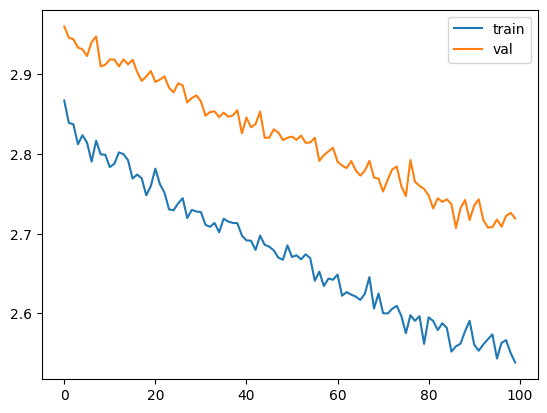

In [ ]:
plt.plot(train_losses)
plt.plot(val_losses)
plt.legend(["train", "val"])

In [ ]:
print(t.decode(model.generate(torch.tensor([[10]]).int(), 1000).tolist()[0]))


Then'd spess the is the knepitess of his of
For Thow'erf am this,
Cayary would coms blut you like st is.
Nople Rut not chreward this oapst the and a loosts
And like, have sise wixted there; and mayt!
I emu' thave sk a say wors, Mame I no man.
Though love
3armed more gread, Maurther'dlelf my fore,
He war preick to seeverbays lom award!,
Agenering'd be upfude--
Do liver:
I erefever lord.

BUTUFir:
He do do ro, I have placiod-- it.

CAPZAMPS:
Iterout too not best thembray
And Now He dused-till is dif word from the come
So surristhiclemery!

DORCOLONIUS:
My canneaion! for my dearst to inse
I'em thane, her as with the sofffter such;
Hap me lord que the go nes, the be contion,
Be joy both; you thee are loosho gone.

Nurse:
Ifffect therefe's clifst comege in his prise
A were hatepe he boot didmangot pive.

LAND:
A is my have deseman toomes: my tithonot they it?

Nursechan of holreate.

CHPRY Bucken have Lord,
I'n us thinee bid, your'd grace. Nibil a grain,
And lWite guancharmough are alv.

F

In [ ]:
print(eval("val"))

2.7044548988342285
